# code_081 · Graphical models and latent states

**Book:** section 16.5. A self-contained probabilistic response-model laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_16_GUIDE.md), [run evidence](../CHAPTER_16_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_081).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
START=time.perf_counter();SEED=1681;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0'}
CPU: Darwin arm64 seed: 1681


<a id="states"></a>
## Known probabilistic states are inferred from noisy measurements

Generate120 steps of a known-parameter HMM with healthy/degraded/failed states. Initial healthy; transition rows[[.95,.05,0],[.01,.94,.05],[0,0,1]]. Failed is absorbing in this fixture. Emission means[0,1,3], SD[.4,.6,.7] in normalized sensor units. No parameters are estimated from this trajectory. Forward filtering uses observations through the current time; backward smoothing and Viterbi decoding use the complete trajectory, so their extra evidence cannot be presented as online performance. A five-step prefix is also exhaustively enumerated over3^5 paths to check likelihood, smoothed marginals and most likely path. State names and dynamics are synthetic, not field degradation evidence.


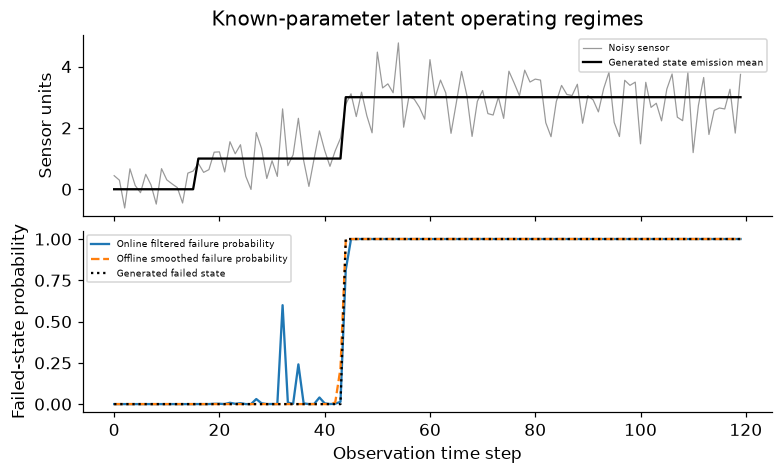

In [2]:
from scipy.special import logsumexp
from scipy.stats import norm
from itertools import product
A=np.array([[.95,.05,0],[.01,.94,.05],[0,0,1.]]);initial=np.array([1.,0,0]);means=np.array([0.,1,3]);sd=np.array([.4,.6,.7]);states=np.zeros(120,dtype=int)
for t in range(1,len(states)):states[t]=rng.choice(3,p=A[states[t-1]])
observations=rng.normal(means[states],sd[states]);logA=np.log(A,out=np.full_like(A,-np.inf),where=A>0);log_initial=np.array([0.,-np.inf,-np.inf]);np.testing.assert_allclose(A.sum(axis=1),1)
def infer(values):
 logB=norm.logpdf(values[:,None],means,sd);T=len(values);f=np.zeros((T,3));scales=np.zeros(T);f[0]=log_initial+logB[0];scales[0]=logsumexp(f[0]);f[0]-=scales[0]
 for t in range(1,T):f[t]=logB[t]+logsumexp(f[t-1][:,None]+logA,axis=0);scales[t]=logsumexp(f[t]);f[t]-=scales[t]
 backward=np.zeros((T,3))
 for t in range(T-2,-1,-1):backward[t]=logsumexp(logA+logB[t+1][None,:]+backward[t+1][None,:],axis=1)-scales[t+1]
 smooth=f+backward;smooth-=logsumexp(smooth,axis=1,keepdims=True);delta=log_initial+logB[0];pointers=np.zeros((T,3),dtype=int)
 for t in range(1,T):scores=delta[:,None]+logA;pointers[t]=np.argmax(scores,axis=0);delta=np.max(scores,axis=0)+logB[t]
 path=np.zeros(T,dtype=int);path[-1]=np.argmax(delta)
 for t in range(T-1,0,-1):path[t-1]=pointers[t,path[t]]
 return np.exp(f),np.exp(smooth),path,float(scales.sum())
filtered,smoothed,path,loglike=infer(observations);prefix=infer(observations[:5]);paths=list(product(range(3),repeat=5));joint=[]
for p in paths:
 value=initial[p[0]]*np.prod(norm.pdf(observations[:5],means[list(p)],sd[list(p)]))*np.prod([A[p[t-1],p[t]] for t in range(1,5)]);joint.append(value)
joint=np.array(joint);weights=joint/joint.sum();brute=np.array([[sum(w for p,w in zip(paths,weights) if p[t]==j) for j in range(3)] for t in range(5)]);np.testing.assert_allclose(prefix[1],brute,atol=1e-12);np.testing.assert_allclose(prefix[3],np.log(joint.sum()),atol=1e-12);np.testing.assert_array_equal(prefix[2],paths[int(np.argmax(joint))]);np.testing.assert_allclose(filtered.sum(axis=1),1);np.testing.assert_allclose(smoothed.sum(axis=1),1)
RESULTS['HMM']={'steps':120,'transition':A.tolist(),'emission_means':means.tolist(),'emission_SD':sd.tolist(),'state_counts':np.bincount(states,minlength=3).tolist(),'filter_marginal_argmax_accuracy':float(np.mean(filtered.argmax(axis=1)==states)),'offline_smooth_marginal_argmax_accuracy':float(np.mean(smoothed.argmax(axis=1)==states)),'offline_Viterbi_path_accuracy':float(np.mean(path==states)),'log_likelihood':loglike,'five_step_enumeration_passed':True,'parameters_fitted':False}
fig,axes=plt.subplots(2,1,figsize=(7,4.2),sharex=True);axes[0].plot(observations,color='.6',lw=.8,label='Noisy sensor');axes[0].plot(means[states],color='black',label='Generated state emission mean');axes[0].set(ylabel='Sensor units',title='Known-parameter latent operating regimes');axes[0].legend(fontsize=6)
axes[1].plot(filtered[:,2],'-',label='Online filtered failure probability');axes[1].plot(smoothed[:,2],'--',label='Offline smoothed failure probability');axes[1].plot(states==2,':',color='black',label='Generated failed state');axes[1].set(xlabel='Observation time step',ylabel='Failed-state probability',ylim=(-.05,1.05));axes[1].legend(fontsize=6);plt.show()


<a id="graphs"></a>
## A probability graph factorizes a distribution

The HMM joint density factors as p(z0)*product transitions*p(observation_t|z_t); arrows describe conditional factors, not causal identification. A separate positive binary undirected chain uses potentials exp(.6*a*b) and exp(.4*b*c), with spins±1 and a global normalizer. Enumeration verifies A independent of C conditional on B. Neither graph is a GNN computation graph: a GNN edge specifies aggregation, not automatically a conditional-independence claim. A separate sixty-step scalar Gaussian state-space fixture with AR coefficient.95, process SD.2 and measurement SD.5 demonstrates known-parameter Kalman filtering of continuous states. These inference audits do not train a degradation model or validate a remaining-life forecast.


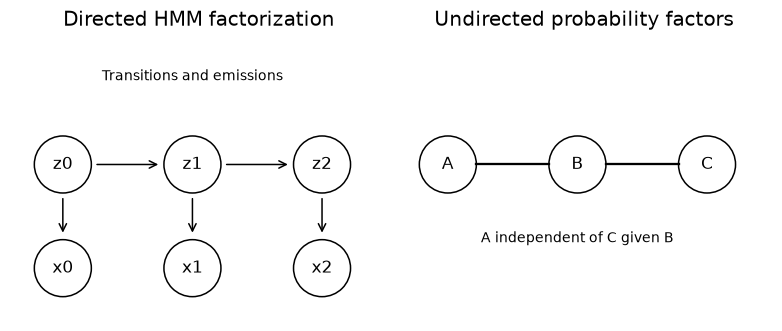

In [3]:
spins=list(product([-1,1],repeat=3));mass=np.array([np.exp(.6*a*b+.4*b*c) for a,b,c in spins]);mass/=mass.sum()
for b in [-1,1]:
 pb=sum(w for (a,bb,c),w in zip(spins,mass) if bb==b);pa=sum(w for (a,bb,c),w in zip(spins,mass) if a==1 and bb==b)/pb
 for c in [-1,1]:
  den=sum(w for (a,bb,cc),w in zip(spins,mass) if bb==b and cc==c);pabc=sum(w for (a,bb,cc),w in zip(spins,mass) if a==1 and bb==b and cc==c)/den;np.testing.assert_allclose(pa,pabc,atol=1e-12)
latent=np.zeros(60);latent[0]=rng.normal();
for t in range(1,60):latent[t]=.95*latent[t-1]+rng.normal(0,.2)
measurements=latent+rng.normal(0,.5,60);estimates=[];variances=[];m=0.;v=1.
for t,value in enumerate(measurements):
 if t:m=.95*m;v=.95**2*v+.2**2
 prior_v=v;gain=v/(v+.5**2);m=m+gain*(value-m);v=(1-gain)*v;assert 0<v<=prior_v;estimates.append(m);variances.append(v)
RESULTS['probability_graphs']={'positive_undirected_chain_states':8,'conditional_independence_checked':True,'GNN_computation_executed':False};RESULTS['continuous_state_filter']={'steps':60,'AR':.95,'process_SD':.2,'measurement_SD':.5,'filter_MSE':float(np.mean((latent-np.array(estimates))**2)),'raw_measurement_MSE':float(np.mean((latent-measurements)**2)),'final_conditional_variance':float(variances[-1]),'parameters_fitted':False}
from matplotlib.patches import FancyArrowPatch,Circle
fig,axes=plt.subplots(1,2,figsize=(7,3.2))
for ax in axes:ax.set(xlim=(-.4,2.5),ylim=(-1.2,1),aspect='equal');ax.axis('off')
ax=axes[0]
for t in range(3):
 for row,label in [(0,f'z{t}'),(-.8,f'x{t}')]:ax.add_patch(Circle((t,row),.22,facecolor='white',edgecolor='black'));ax.text(t,row,label,ha='center',va='center')
 ax.add_patch(FancyArrowPatch((t,-.24),(t,-.55),arrowstyle='->',mutation_scale=12))
 if t<2:ax.add_patch(FancyArrowPatch((t+.24,0),(t+.76,0),arrowstyle='->',mutation_scale=12))
ax.set_title('Directed HMM factorization');ax.text(1,.65,'Transitions and emissions',ha='center',fontsize=9)
ax=axes[1]
for t,label in enumerate(['A','B','C']):ax.add_patch(Circle((t,0),.22,facecolor='white',edgecolor='black'));ax.text(t,0,label,ha='center',va='center')
for t in range(2):ax.plot([t+.22,t+.78],[0,0],color='black')
ax.text(1,-.6,'A independent of C given B',ha='center',fontsize=9);ax.set_title('Undirected probability factors');plt.show()


In [4]:
summary={'example_id':'code_081','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['directed probability factorization and latent regimes', 'forward filtering versus offline smoothing and Viterbi', 'exact enumeration and undirected conditional independence', 'continuous Gaussian state-space filtering'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["directed probability factorization and latent regimes", "forward filtering versus offline smoothing and Viterbi", "exact enumeration and undirected conditional independence", "continuous Gaussian state-space filtering"], "elapsed_seconds": 0.151, "example_id": "code_081", "hardware": "Darwin arm64 CPU", "results": {"HMM": {"emission_SD": [0.4, 0.6, 0.7], "emission_means": [0.0, 1.0, 3.0], "filter_marginal_argmax_accuracy": 0.9916666666666667, "five_step_enumeration_passed": true, "log_likelihood": -125.39832437277302, "offline_Viterbi_path_accuracy": 0.9833333333333333, "offline_smooth_marginal_argmax_accuracy": 0.9916666666666667, "parameters_fitted": false, "state_counts": [16, 28, 76], "steps": 120, "transition": [[0.95, 0.05, 0.0], [0.01, 0.94, 0.05], [0.0, 0.0, 1.0]]}, "continuous_state_filter": {"AR": 0.95, "filter_MSE": 0.0673537922366018, "final_conditional_variance": 0.0754761346655404, "measurement_SD": 0.5, "parameters_fitte